# Plots

(json-to-plots-butadiene1)=
## Plotting

In [1]:
####################################################
### Import Libraries and set up global variables ###
####################################################

from pathlib import Path
import json

import sys

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

# Install packages only if needed
# Google Colab does not include every Python package
#
# Psi4 cannot be installed with pip. On Colab we first install conda
# (condacolab), which RESTARTS the session. After the restart, run
# this cell again and Psi4 will be installed with conda.
try:                  # if the package exists import it, otherwise install it
    import psi4
except ImportError:
    if IN_COLAB:
        !pip -q install condacolab
        import condacolab
        condacolab.install()
        !mamba install -q -y -c conda-forge psi4
    import psi4

try:
    import py3Dmol
except ImportError:
    !pip -q install py3Dmol
    import py3Dmol

try:
    import skimage          # scikit-image draws the static orbital and density surfaces
except ImportError:
    !pip -q install scikit-image
    import skimage

# Standard imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Style sheets and helper functions from the book's GitHub repository
if IN_COLAB and not Path("styles/tufte.mplstyle").exists():
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/tufte.mplstyle
    !wget -q -P styles https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/styles/S2_classic2.mplstyle
    !wget -q -N https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/psi4_helpers.py

# The methane structure file used in this chapter
if IN_COLAB and not Path("data/methane.xyz").exists():
    !wget -q -P data https://raw.githubusercontent.com/blinkletter/UsingPsi4v2/main/ch3/3A-methane/data/methane.xyz

if IN_COLAB:
    plt.style.use("styles/tufte.mplstyle")
else:
    sys.path.insert(0, "../..")                 # psi4_helpers.py is two folders up
    plt.style.use("../../styles/tufte.mplstyle")

import psi4_helpers as ph

# Psi4 output (.out, .log, .molden, cube files, scans) goes into output/, which is not kept in git.
# Small results files that another page reads (.json, .csv) go into data/, which is kept in git.
output_dir = Path("output")
output_dir.mkdir(parents=True, exist_ok=True)
data_dir = Path("data")
data_dir.mkdir(parents=True, exist_ok=True)

# 3D pictures: False = static images (as in the book); True = rotatable py3Dmol viewers
INTERACTIVE = True

In [13]:
# recreate the result object from the json file
data_dir = Path("data")
with open(data_dir / "butadiene_scan.json") as f:
    scan = json.load(f)

print("List of dictionaries has been imported. Keys in each dictionay are... ")
print(list(scan[0].keys()))

List of dictionaries has been imported. Keys in each dictionay are... 
['D', 'E', 'steps', 'E_homo', 'E_lumo', 'sym', 'PG', 'xyz', 'Z', 'var']


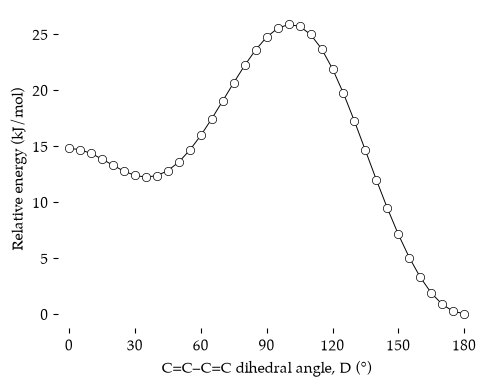

In [15]:
scan.sort(key=lambda point: point["D"])          # make sure points are in order of D

Ds = [point["D"] for point in scan]
Es = [point["E"] for point in scan]              # hartree
E_min = min(Es)
E_rel = [(E - E_min) * 2625.5 for E in Es]       # kJ/mol relative to the lowest point

plt.style.use("../../styles/tufte.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
ax.plot(Ds, E_rel, color="black", linewidth=0.7, zorder=1)
ax.plot(Ds, E_rel, linestyle="none", marker="o", markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("Relative energy (kJ/mol)")
ax.set_xlim(-5, 185)
ax.set_xticks([0,30,60,90,120,150,180])

plt.show()

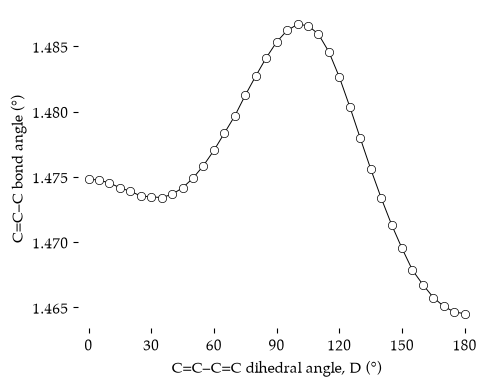

In [25]:
scan.sort(key=lambda point: point["D"])          # make sure points are in order of D

Ds = [point["D"] for point in scan]
As = [point["var"]["rCCcent"] for point in scan]              # hartree

plt.style.use("../../styles/tufte.mplstyle")
fig, ax = plt.subplots(nrows=1, ncols=1, figsize=(5,4))
ax.plot(Ds, As, color="black", linewidth=0.7, zorder=1)
ax.plot(Ds, As, linestyle="none", marker="o", markerfacecolor="white",
        markeredgecolor="black", markeredgewidth=0.5, zorder=2)
ax.set_xlabel("C=C–C=C dihedral angle, D (°)")
ax.set_ylabel("C=C–C bond angle (°)")
ax.set_xlim(-5, 185)
ax.set_xticks([0,30,60,90,120,150,180])
#ax.set_ylim(123.9, 127.3)
#ax.set_yticks([124,125,126,127])

plt.show()